# The dataset and business need

| Column | Type | Note |
|---|---|---|
| `ID` | Identifier | Index, not a feature |
| `customer_id` | Identifier | Kept out of the model; used to group the split |
| `repeat_purchase_90d` | Target | Binary |
| `random_noise` | Noise | Excluded from features |
| `document_series` | Categorical | 3 levels |
| `warehouse` | Categorical | 2 levels |
| `invoice_count_current_purchase` | Numeric count | Values 1-5 |
| `N_ Detalhes` | Numeric count | |
| `prior_purchase_count` | Numeric count | |
| `purchase_count_30d` | Numeric count | Check window direction |
| `purchase_count_90d` | Numeric count | Check window direction |
| `purchase_count_180d` | Numeric count | Check window direction |
| `purchase_count_365d` | Numeric count | Check window direction |
| `days_since_previous_purchase` | Numeric | Blank = first purchase? |
| `customer_tenure_days` | Numeric | |
| `prior_mean_gap_days` | Numeric | |
| `prior_std_gap_days` | Numeric | |
| `Total a Pagar` | Numeric | |
| `Total Bruto` | Numeric | Likely correlated with `Total a Pagar` |
| `Total Liquido` | Numeric | Likely correlated with `Total a Pagar` |
| `Total Imp_` | Numeric | |
| `Total Portes` | Numeric | |
| `Total Desc_ Global` | Numeric | |
| `Total Desc_ Linha` | Numeric | |
| `Custo` | Numeric | |
| `prior_total_spend` | Numeric | |
| `prior_mean_purchase_value` | Numeric | 16 negatives |
| `prior_std_purchase_value` | Numeric | |
| `prior_min_purchase_value` | Numeric | |
| `prior_max_purchase_value` | Numeric | |
| `spend_30d` | Numeric | Check window direction |
| `spend_90d` | Numeric | Check window direction |
| `spend_180d` | Numeric | Check window direction |
| `spend_365d` | Numeric | 15 negatives; check window direction |

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import joblib
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from math import ceil

In [6]:
train_df = pd.read_csv("../data/train.csv", index_col="ID")
clients_df = pd.read_csv("../data/clientes.csv", index_col="customer_id")
test_df = pd.read_csv("../data/test.csv")

# Exploring the data

In [7]:
train_df.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [8]:
train_df["purchase_date"] = pd.to_datetime(train_df["purchase_date"], format="%Y-%m-%d")

In [32]:
identifiers = ["customer_id"]
target = "repeat_purchase_90d"

numeric = [c for c in train_df.columns
           if c not in identifiers + [target]
           and pd.api.types.is_numeric_dtype(train_df[c])]
categorical = [c for c in train_df.columns
               if c not in identifiers + [target] + numeric]

In [10]:
low_cardinality = {c: train_df[c].nunique() for c in numeric if train_df[c].nunique() <= 10}
levels = train_df[categorical].nunique().sort_values(ascending=False)
print(f"Numeric columns with low cardinality: {low_cardinality}")
for column in levels[levels <= 4].index:
    print(column, sorted(train_df[column].dropna().unique()))

Numeric columns with low cardinality: {'invoice_count_current_purchase': 5}
document_series ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']
warehouse ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']


There are no inconsistencies in the categorical values.

In [31]:
per_customer = train_df.groupby("customer_id").size()
print(f"\nsurplus rows on 'customer_id': {train_df.duplicated(subset='customer_id').sum()}")
print(f"rows sharing a 'customer_id': {per_customer[per_customer > 1].sum()}"
      f" across {(per_customer > 1).sum()} customers")
print("records per customer:", per_customer.value_counts().to_dict())


surplus rows on 'customer_id': 5924
rows sharing a 'customer_id': 6377 across 453 customers
records per customer: {1: 157, 2: 84, 3: 49, 4: 47, 6: 25, 5: 23, 7: 21, 10: 14, 15: 13, 9: 13, 11: 12, 8: 11, 13: 10, 21: 9, 14: 8, 18: 8, 24: 7, 17: 7, 16: 6, 29: 5, 26: 5, 22: 4, 12: 4, 50: 4, 19: 4, 35: 3, 31: 3, 23: 3, 30: 3, 28: 3, 89: 2, 42: 2, 54: 2, 41: 2, 63: 2, 51: 2, 32: 2, 37: 2, 27: 2, 36: 2, 277: 1, 43: 1, 38: 1, 25: 1, 74: 1, 81: 1, 203: 1, 33: 1, 49: 1, 59: 1, 39: 1, 67: 1, 73: 1, 48: 1, 53: 1, 66: 1, 62: 1, 55: 1, 80: 1, 112: 1, 60: 1, 47: 1, 40: 1, 56: 1, 20: 1}


## Analysing the target

Guaranteed the fact that no repeat_purchase_90d value is null (NA), we proceed to the analysis of the target column. The first step is to count absolute and relative the frequency of 1's and 0's. Our aim is to discover other features patterns inside the distribution of these binary values.

In [15]:
count_target = train_df['repeat_purchase_90d'].value_counts()

target_prop = count_target.to_frame("count").assign(proportion=lambda d: d["count"] / d["count"].sum())
target_prop

,count,proportion
repeat_purchase_90d,,
1,3654,0.559229
0,2880,0.440771


55.92% of the target rows are 1 and 44,08% are 0, therefore our target column is relatively balanced.

In [16]:
train_df[numeric].groupby(train_df["repeat_purchase_90d"]).mean().round(2).T

repeat_purchase_90d,0,1
Total a Pagar,808.56,1017.58
Total Bruto,762.81,983.17
Total Liquido,680.06,846.70
Total Imp_,128.49,170.88
Total Portes,1.16,1.15
Total Desc_ Global,0.42,0.30
Total Desc_ Linha,82.33,136.17
Custo,299.83,350.45
N_ Detalhes,20.79,22.10
invoice_count_current_purchase,1.05,1.08


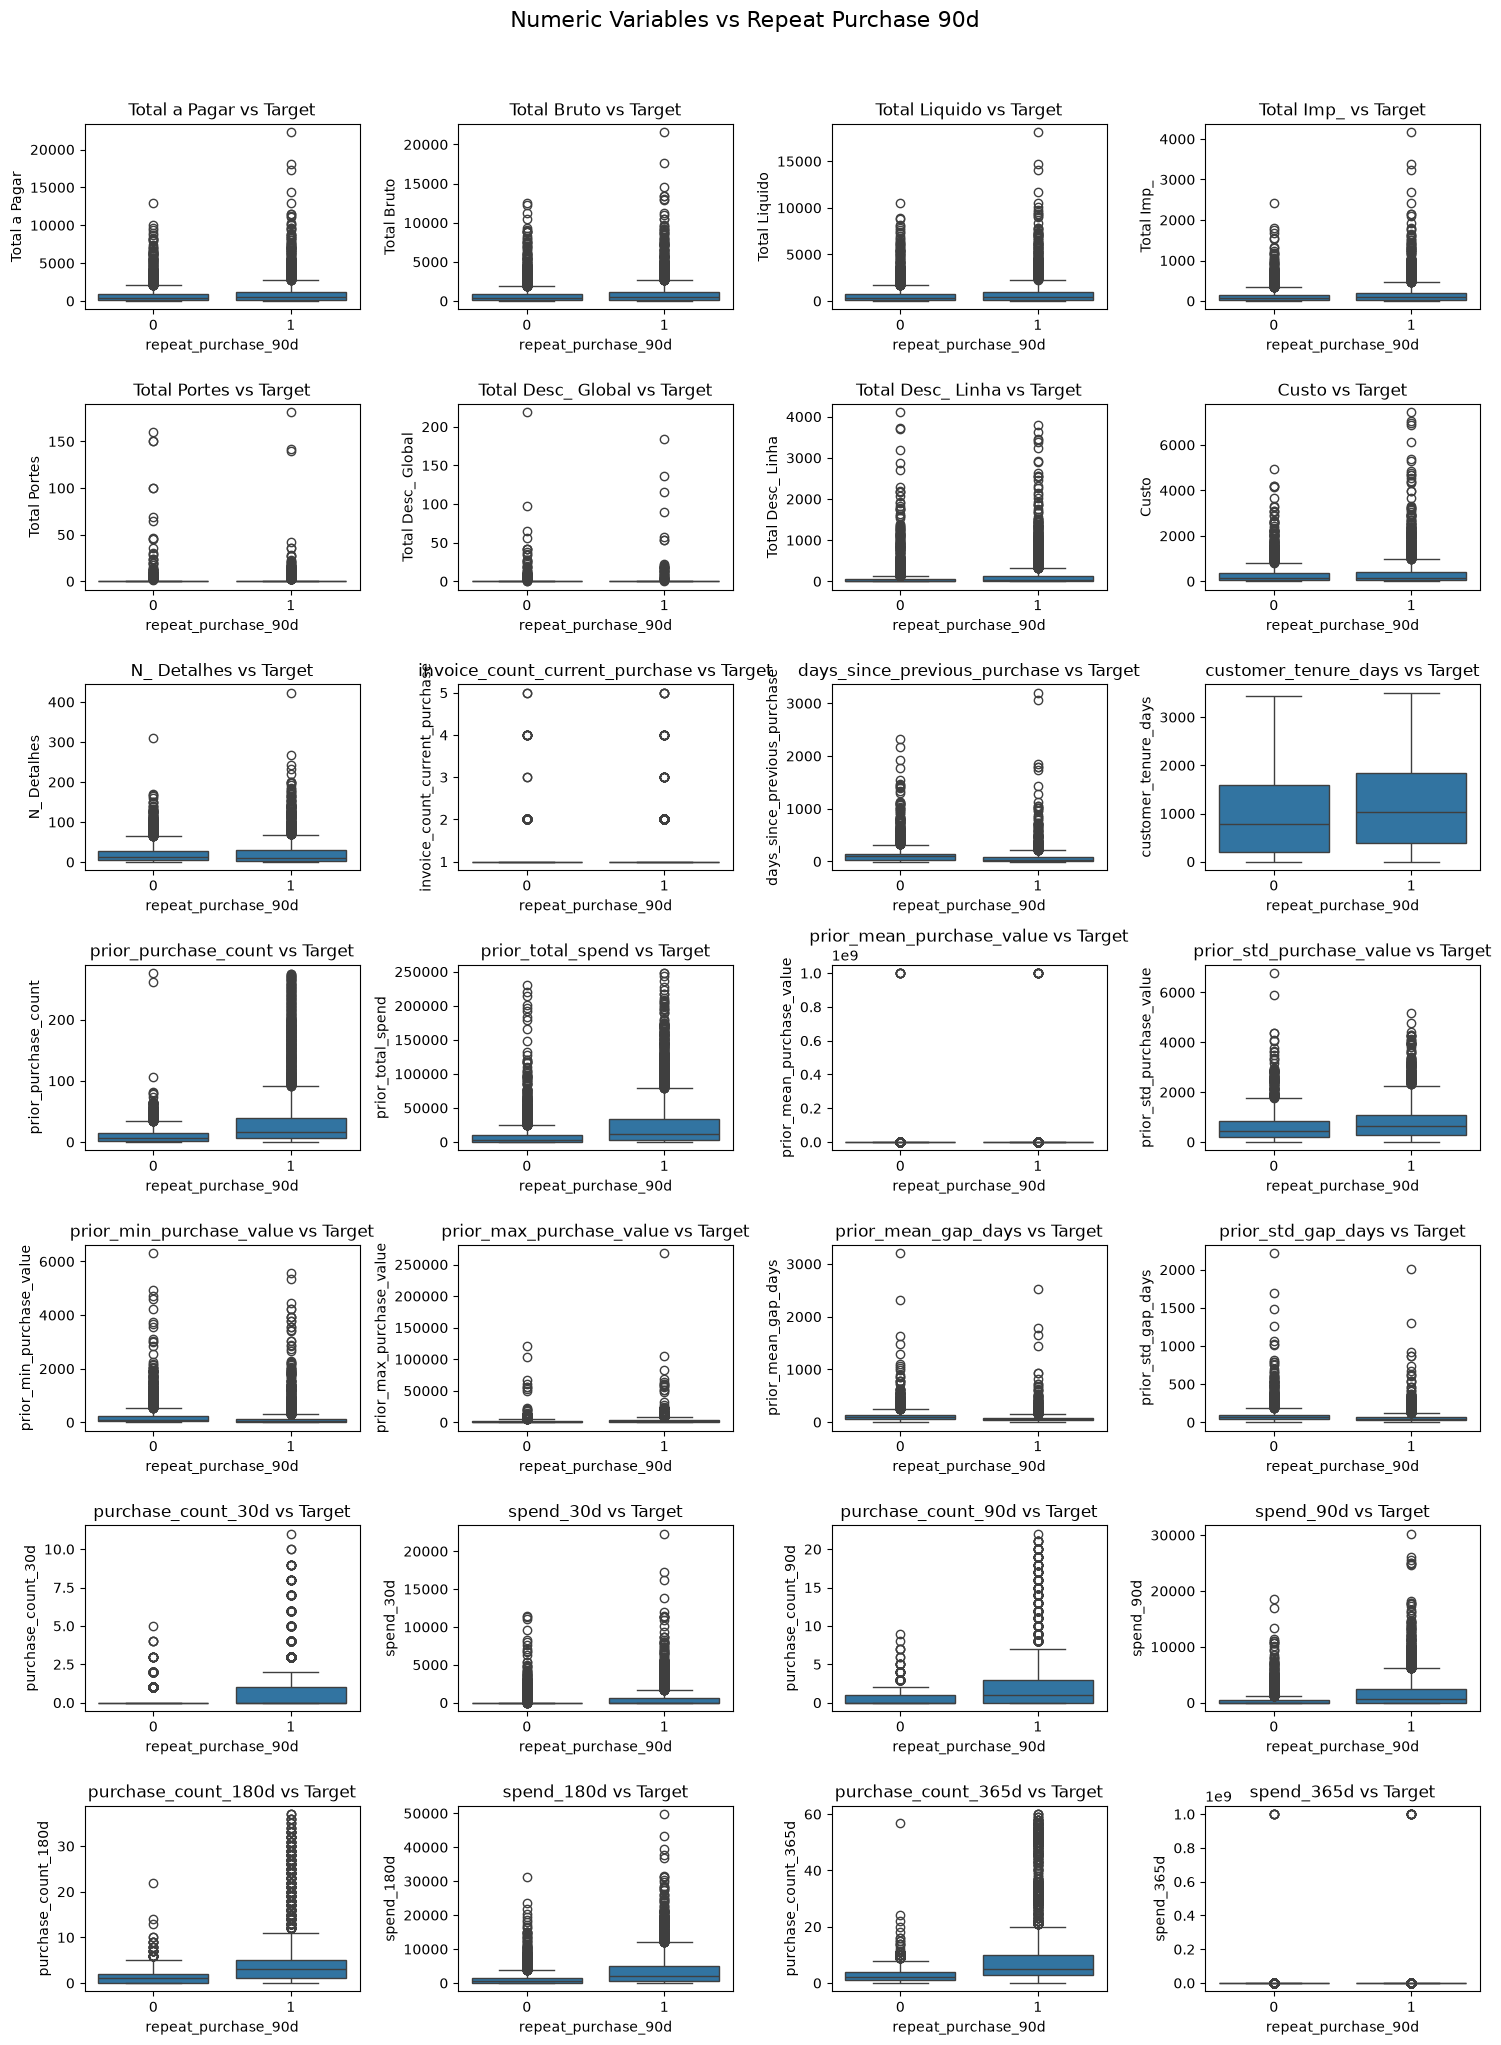

In [17]:
# Examining numerical features in relation to the target using Boxplots (checking which features are good predictors of the target)
fig, axes = plt.subplots(ceil(len(numeric) / 4), 4, figsize=(15, 20))

# Iterarating each box plot and adding x='repeat_purchase_90d'
for ax, feat in zip(axes.flatten(), numeric): 
    sns.boxplot(data=train_df, x='repeat_purchase_90d', y=feat, ax=ax)
    ax.set_title(f'{feat} vs Target')

# hidding the empty graphs that would appear at the end
for ax in axes.flatten()[len(numeric):]:
    fig.delaxes(ax)

# Layout and title
plt.suptitle("Numeric Variables vs Repeat Purchase 90d", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## EDA of the numeric columns

Next we analyse the distribution of our numerical columns, using descriptive statistics and histograms.

In [18]:
summary = train_df[numeric].describe().T
shape = summary.copy()
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = train_df[numeric].skew()
shape["% zeros"] = 100 * (train_df[numeric] == 0).mean()

shape[["mean", "50%", "mean/median", "skew", "% zeros"]].round(2)

,mean,50%,mean/median,skew,% zeros
Total a Pagar,925.56,476.74,1.94,4.21,0.00
Total Bruto,886.15,445.74,1.99,4.31,0.00
Total Liquido,773.34,389.91,1.98,4.15,0.00
Total Imp_,152.22,79.74,1.91,4.84,3.26
Total Portes,1.15,0.00,NaN,19.55,82.89
Total Desc_ Global,0.35,0.00,NaN,27.46,97.32
Total Desc_ Linha,112.47,13.13,8.57,5.92,37.36
Custo,328.17,152.54,2.15,4.61,7.44
N_ Detalhes,21.52,11.00,1.96,2.98,0.00
invoice_count_current_purchase,1.07,1.00,1.07,6.44,0.00


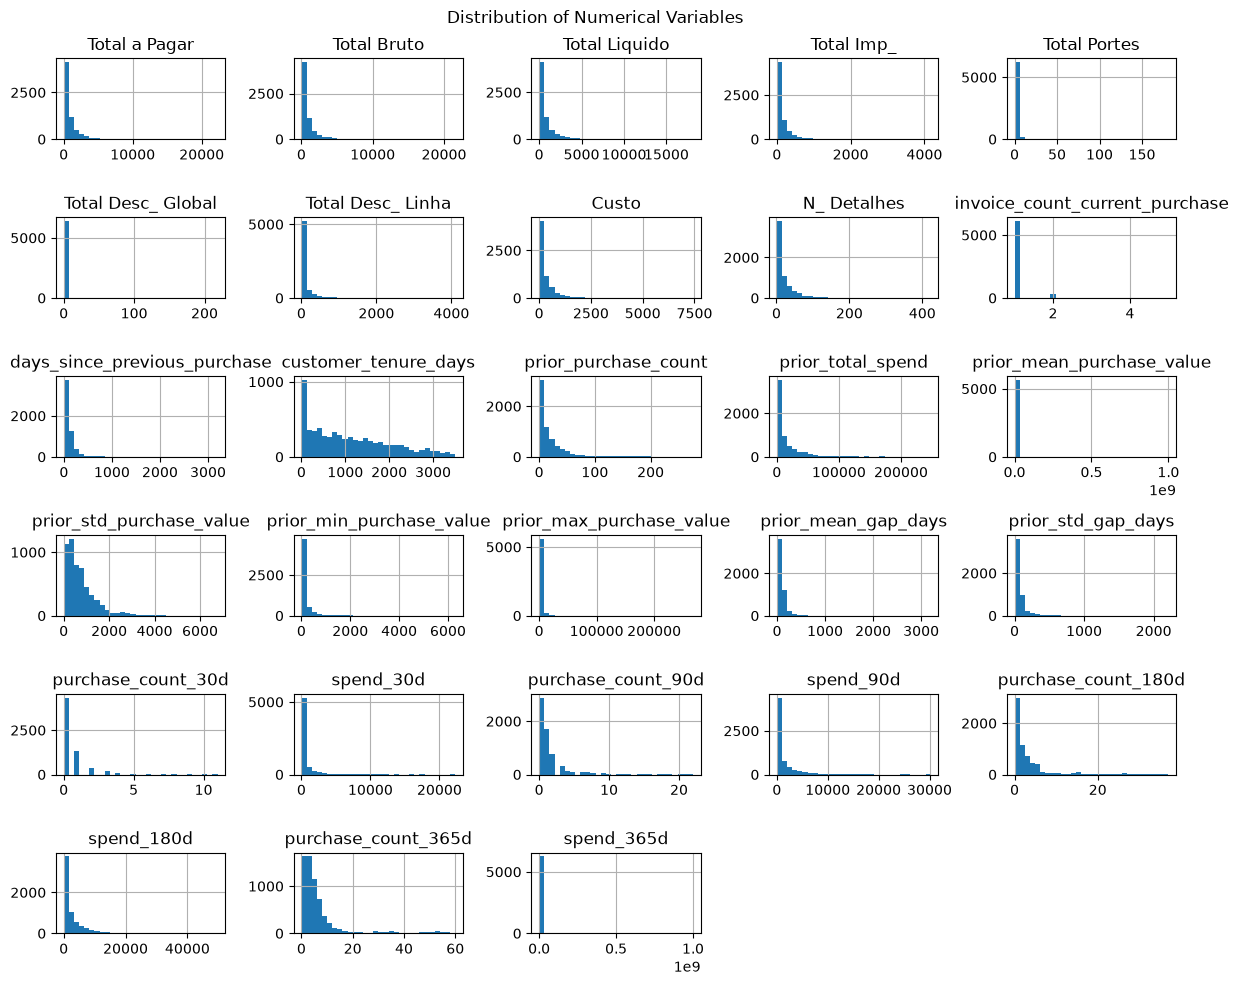

In [19]:
# Ploting the distributions of the numerical features
# we want to explore the skewness of each variable
# and to understand if there are negative values where only positive numbers make sense, or extreme values far from the mean
# we also want to see if the scale of some variables is different from others to see if we will need to do scaling

train_df[numeric].hist(figsize=(12, 10), bins=30)
plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

From this analysis it is visible that the numeric columns are highly skewed to the right. We also have some columns with high percentage of zeros, the worst column being Total Desc_ Global with 97.32% zeros.

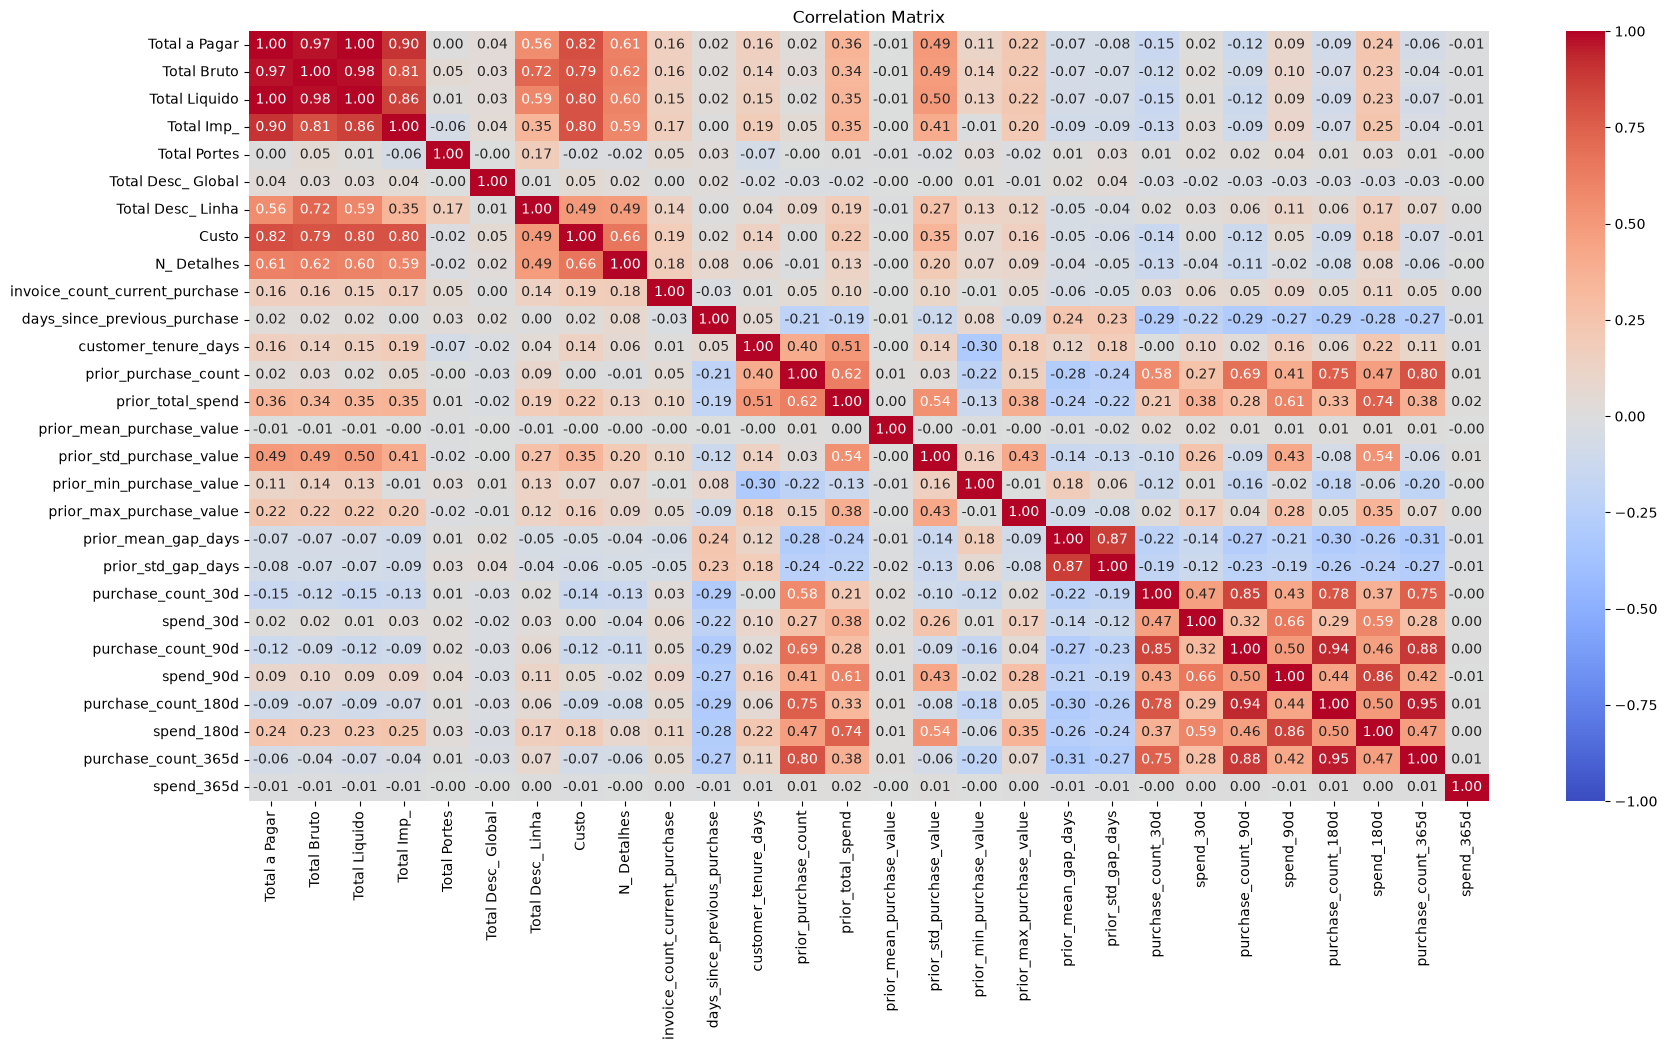

In [ ]:
# multivariate relationships (Calculating Pearson's correlation coefficient between each feature)
plt.figure(figsize=(20, 10))
sns.heatmap(train_df[numeric + [target]].corr(), fmt=".2f", annot=True,
            cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation Matrix")
plt.show()

**Multivariate analysis: correlation matrix (Pearson)**

The matrix shows five groups of related variables and two columns that look anomalous.

1. **Invoice totals (r = 0.81-1.00).** `Total a Pagar`, `Total Bruto`, `Total Liquido` and `Total Imp_` are almost perfectly correlated, as expected from the accounting identities between them. `Custo` (0.79-0.82) and, more weakly, `N_ Detalhes` (≈0.60) and `Total Desc_ Linha` (0.56-0.72) move with them. Larger invoices have more lines, higher cost and larger discounts.
2. **Purchase counts by window (r = 0.75-0.95).** `purchase_count_30d`, `_90d`, `_180d` and `_365d` are highly correlated, because the shorter windows are nested inside the longer ones. They also correlate with `prior_purchase_count` (0.58-0.80).
3. **Spend by window (r = 0.66-0.86).** `spend_30d`, `spend_90d` and `spend_180d` are related to each other and to `prior_total_spend` (0.61-0.74). `spend_365d` is the exception (see below).
4. **Purchase gaps (r = 0.87).** `prior_mean_gap_days` and `prior_std_gap_days` are strongly related. Both are negatively correlated with the purchase counts (-0.21 to -0.31): customers who buy more often have shorter gaps between purchases.
5. **Customer history.** `customer_tenure_days` is moderately correlated with `prior_purchase_count` (0.40) and `prior_total_spend` (0.51), as longer-standing customers have bought more.

**Weak or independent variables.** `Total Portes`, `Total Desc_ Global` and `invoice_count_current_purchase` are close to uncorrelated with all other variables (|r| < 0.2).

**Anomalies to investigate.** `spend_365d` and `prior_mean_purchase_value` have a correlation of about 0 with every other variable, including `spend_180d` and `prior_total_spend`, which they should track closely. Both columns contain negative values and extreme outliers, which dominate Pearson's coefficient.

**Implications.** Most of the strong correlations are structural (accounting identities and nested time windows), so they carry little new information. Keep one representative per group, or derive ratios, instead of keeping all columns.

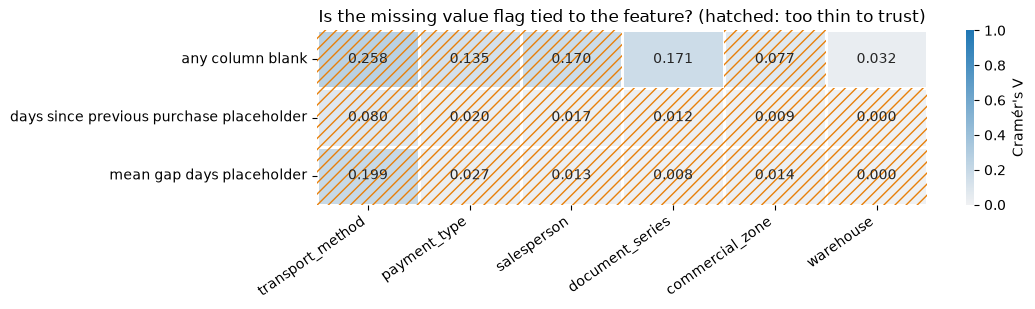

In [34]:
test_columns = [c for c in categorical if c != "purchase_date"]

rows = []
for missing_source, flag in missing_flags.items():
    for column in test_columns:
        table = pd.crosstab(flag, train_df[column])
        chi2, p, _, expected = chi2_contingency(table)
        rows.append({
            "missing source": missing_source,
            "feature": column,
            "chi2": chi2,
            "Cramer's V": association(table, method="cramer", correction=True),
            "p": p,
            "min expected count": expected.min(),
        })
association_table = pd.DataFrame(rows)

strength = association_table.pivot(
    index="missing source", columns="feature", values="Cramer's V")
too_thin = association_table.pivot(
    index="missing source", columns="feature", values="min expected count") < 5
by_strength = strength.loc["days since previous purchase placeholder"].sort_values(
    ascending=False).index
strength, too_thin = strength[by_strength], too_thin[by_strength]

fig, ax = plt.subplots(figsize=(11, 3.2))
sns.heatmap(strength, vmin=0, vmax=1, annot=True, fmt=".3f", linewidths=2,
            cmap=sns.light_palette("#1F77B4", as_cmap=True),
            cbar_kws={"label": "Cramér's V"}, ax=ax)
# Hatched where the minimum expected count is under 5: that cell's colour is
# arithmetic rather than evidence, and hatching says so without hiding it.
for row, column in zip(*np.where(too_thin.values)):
    ax.add_patch(plt.Rectangle((column, row), 1, 1, fill=False, hatch="///",
                               edgecolor="#E8800A", linewidth=0))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Is the missing value flag tied to the feature? (hatched: too thin to trust)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()

## Computing values from other columns

In [23]:
train_copy = train_df.copy()
train_copy.shape

(6534, 38)

In [ ]:
cols = numeric
check = pd.DataFrame({
    "min": train_df[cols].min(),
    "n_negative": (train_df[cols] < 0).sum()
})
check[check["n_negative"] > 0]

,min,n_negative
days_since_previous_purchase,-4.000000,16
prior_mean_purchase_value,-2478.658478,16
prior_mean_gap_days,-4.000000,16
spend_365d,-159115.175535,15


There are only four columns with negative values. Two of this rows -4 as their minimum value so next we analysed the distinct negative values of these columns to check wether these were filler values for when we don't have data or if they were errors.

In [ ]:
for c in ["days_since_previous_purchase", "prior_mean_gap_days", "prior_mean_purchase_value", "spend_365d"]:
    print(train_df.loc[train_df[c] < 0, c].value_counts())

days_since_previous_purchase
-4.0    16
Name: count, dtype: int64
prior_mean_gap_days
-4.0    16
Name: count, dtype: int64
prior_mean_purchase_value
-110.147097     1
-409.791667     1
-218.266392     1
-417.917143     1
-779.030000     1
-212.360622     1
-366.120000     1
-2478.658478    1
-693.010000     1
-757.480000     1
-305.930000     1
-504.580000     1
-357.193750     1
-162.482308     1
-883.510000     1
-885.097111     1
Name: count, dtype: int64
spend_365d
-3456.320000      1
-1230.720000      1
-167.180000       1
-753.510000       1
-2648.440000      1
-2169.910000      1
-1443.640000      1
-5133.040000      1
-14740.290000     1
-4196.900000      1
-1620.830000      1
-6795.470000      1
-159115.175535    1
-295.380000       1
-12638.050000     1
Name: count, dtype: int64


While in prior_mean_purchase_value and spend_365d all negative values are different, in the days_since_previous_purchase and prior_mean_gap_days columns all negative values are -4. This number appears to be a "filler" value for when we don't have information.

In [ ]:
rows_with_null = train_df.isna().any(axis=1)
per_column = train_df.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(train_df):,}"
                        f" ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {train_df.shape[1]}",
    "null cells": f"{train_df.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"2,605 of 6,534 (39.87%)"
columns with a null,36 of 38
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


Almost 40% of all rows have missing values, with a total of 9818 cells missing.

In [ ]:
train_df.isna().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

In [ ]:
train_df[numeric+categorical].isna().all(axis=1).sum()

np.int64(65)

It appears that 65 rows have missing values (NaN) in all columns except customer_id and repeat_purchase_90d (target).

In [24]:
columns_null = numeric + categorical
train_copy = train_copy.dropna(subset=columns_null, how="all")
train_copy[columns_null].isna().sum()[lambda s: s > 0]

days_since_previous_purchase     796
prior_mean_purchase_value        797
prior_std_purchase_value        1048
prior_min_purchase_value         603
prior_max_purchase_value         603
prior_mean_gap_days             1243
prior_std_gap_days              1413
spend_365d                       195
payment_type                     195
salesperson                      194
transport_method                 196
warehouse                        195
dtype: int64

Now we only have 12 columns with missing values, instead of the original 36.

In [ ]:
purchase_value_columns = ['prior_purchase_count','prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value']
train_copy.loc[(train_copy['prior_mean_purchase_value'].isna()) & (train_copy['prior_purchase_count'] != 0), purchase_value_columns]

,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value
ID,,,,,,
10000056,60.0,63963.67,NaN,1562.200411,6.62,9323.40
10000069,32.0,34721.00,NaN,1402.096827,11.37,7139.60
10000081,7.0,4614.70,NaN,657.365890,122.96,2039.27
10000129,25.0,30396.09,NaN,1326.866802,3.35,5019.81
10000153,1.0,1855.81,NaN,NaN,1855.81,1855.81
...,...,...,...,...,...,...
10007436,49.0,46431.92,NaN,1117.614107,28.88,5217.94
10007474,2.0,57.01,NaN,27.471098,9.08,47.93
10007484,28.0,61128.06,NaN,1650.047686,11.02,6790.17


There are 194 rows where customers have total spend and purchase counts, but their mean purchase value was not recorded (NaN). We can get the prior mean purchase value by dividing prior total spend by the prior purchase count.

In [ ]:
train_copy.loc[(train_copy['prior_mean_purchase_value'] < 0) & (train_copy['prior_purchase_count'] != 0), purchase_value_columns]

,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value
ID,,,,,,
10000018,31.0,3414.56,-110.147097,124.138784,0.93,552.37
10000519,6.0,2458.75,-409.791667,242.646274,127.62,836.19
10000536,194.0,42343.68,-218.266392,272.351550,4.54,2306.25
10001157,7.0,2925.42,-417.917143,112.612828,249.34,567.23
10001375,5.0,3895.15,-779.030000,1128.918228,61.50,2779.80
10001461,209.0,44383.37,-212.360622,265.640842,4.54,2306.25
10002281,1.0,366.12,-366.120000,NaN,366.12,366.12
10002605,46.0,114018.29,-2478.658478,1587.243494,4.50,6790.17
10002989,9.0,6237.09,-693.010000,517.133910,82.40,1521.68


The mean in this rows is the negative version of the real mean, so we can also compute the mean from these rows

In [ ]:
missing_mean = (train_copy['prior_mean_purchase_value'].isna()) & (train_copy['prior_purchase_count'] != 0)
negative_mean = (train_copy['prior_mean_purchase_value'] < 0) & (train_copy['prior_purchase_count'] != 0)

train_copy.loc[missing_mean, 'prior_mean_purchase_value'] = train_copy.loc[missing_mean, 'prior_total_spend']/train_copy.loc[missing_mean, 'prior_purchase_count']
train_copy.loc[negative_mean, 'prior_mean_purchase_value'] = train_copy.loc[negative_mean, 'prior_total_spend']/train_copy.loc[negative_mean, 'prior_purchase_count']

In [29]:
missing_max_min = (train_copy['prior_max_purchase_value'].isna()) & (train_copy['prior_min_purchase_value'].isna())
count_value_is_zero = (train_copy['prior_total_spend'] == 0) & (train_copy['prior_purchase_count'] == 0)
train_copy.loc[missing_max_min & count_value_is_zero, purchase_value_columns]

,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value
ID,,,,,,
10000032,0.0,0.0,NaN,NaN,NaN,NaN
10000034,0.0,0.0,NaN,NaN,NaN,NaN
10000052,0.0,0.0,NaN,NaN,NaN,NaN
10000058,0.0,0.0,NaN,NaN,NaN,NaN
10000068,0.0,0.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
10007621,0.0,0.0,NaN,NaN,NaN,NaN
10007631,0.0,0.0,NaN,NaN,NaN,NaN
10007656,0.0,0.0,NaN,NaN,NaN,NaN


Existem muitos valores que estão NaN porque não existem compras anteriores (prior_purchase_count e prior_total_spend = 0). As 603 linhas sem valores de prior_max_purchase_value e prior_min_purchase value é quando não há compras anteriores. Neste caso acho qur podíamos por os valores em 0 (se compraram 0 e gastaram 0, o máximo e o mínimo são 0). Nestes casos std value e mean value também são 0. Fazemos o mesmo?

THis inputs 0 for both the max and the minimum prior purchase values in all rows where both features are missing and then it shows as a summary series listing only the customers that still contain missing values along their updated count of NaN. 

In [37]:
train_copy.loc[missing_max_min, 'prior_max_purchase_value'] = 0
train_copy.loc[missing_max_min, 'prior_min_purchase_value'] = 0

In [36]:
gap_days = ['purchase_date', 'customer_tenure_days', 'days_since_previous_purchase', 'prior_mean_gap_days', 'prior_std_gap_days', 'prior_purchase_count', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d']
rows_to_substitute = (train_copy['prior_mean_gap_days'].isna()) & (train_copy['prior_purchase_count'] > 1) & (train_copy['days_since_previous_purchase'] >= 0)

train_copy.loc[rows_to_substitute, 'prior_mean_gap_days'] = (train_copy.loc[rows_to_substitute, 'customer_tenure_days']-train_copy.loc[rows_to_substitute, 'days_since_previous_purchase'])/(train_copy.loc[rows_to_substitute, 'prior_purchase_count']-1)

For customers that have 0 prior purchases it's normal for them to not have days_since_previous_purchase , prior_mean_gap_days and prior_std_gap_days since they have never bought anything before.
For customers with 1 prior purchase, they do have days_since_previous_purchase but since they only purchased once, they don't have a prior_mean_gap_days because there's no second purchase to measure the gap days. This also means there won't be a prior_std_gap_days.
For customers with 2 prior purchases, there is only 1 gap, so we can calculate the prior_mean_gap_days but not the prior_std_gap_days since we can't calcluate a variantion from a single number.

So how do we fill these missing values?
We can fill prior_std_gap_days with 0 for these cases because customers with 0; 1 or 2 purchases have no variation in their gaps.
For the customers that purchases 1 time, we can set prior_mean_gap_days eaqual to the days_since_previous_purchase. And for customers with 0 purchases we set the prior_mean_gap_days to 0.

In [40]:
count = train_copy["prior_purchase_count"]
gap_cols = ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days"]
#checking that custumoers with 3 or more purchaseshave no NaNs
print(train_copy.loc[count>=3, gap_cols].isna().sum()) 

#custumers with 1 prior_purchase: we want mean gap to be equal to days since that purchase
one_purchase = (count==1) & train_copy["prior_mean_gap_days"].isna()
train_copy.loc[one_purchase, "prior_mean_gap_days"] = train_copy.loc[one_purchase, "days_since_previous_purchase"]

# filling the NaNs with 0 for the customers with 0 to 2 purchases
less_purchases = count <=2
for col in gap_cols:
    train_copy.loc[less_purchases,col] = train_copy.loc[less_purchases,col].fillna(0.0)

# checking if the NaNs are 0 for all these columns
print(train_copy[gap_cols].isna().sum())

days_since_previous_purchase    0
prior_mean_gap_days             0
prior_std_gap_days              0
dtype: int64
days_since_previous_purchase    0
prior_mean_gap_days             0
prior_std_gap_days              0
dtype: int64


In [44]:
# Check se o codigo acima ta correto!
# For the customers with more than 3 purchases do we substitute with the median????